In [1]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import sklearn.model_selection
import subprocess, tqdm, json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from aifes import keras2aifes

c:\Users\foltz\Documents\ISMIN\3A\Embedded_Systems\Embedded_Neural_Network_on_MCU\Projet_Embedded_AI_MCU\.venv\Lib\site-packages\aifes\aifes_code_generator\aifes_code_creator.py:16: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
GPU_ID = 0
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.set_visible_devices(gpus[GPU_ID], 'GPU')
        tf.config.experimental.set_memory_growth(gpus[GPU_ID], True)
    except RuntimeError as e:
        print(e)

In [3]:
def imshow(img, title):
    plt.imshow(img, cmap = "binary")
    plt.title(str(title))
    plt.show()

def plot_value_array(i, predictions_array, true_label, num_classes):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(num_classes))
    plt.yticks([])
    thisplot = plt.bar(range(num_classes), predictions_array, color="#777777")
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)

    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('blue')

def plot_image(i, predictions_array, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    plt.imshow(img, cmap=plt.cm.binary)

    predicted_label = np.argmax(predictions_array)
    if predicted_label == true_label:
        color = 'blue'
    else:
        color = 'red'

    plt.xlabel("{} {:2.0f}% ({})".format(predicted_label,
                                    100*np.max(predictions_array),
                                    true_label),
                                    color=color)

def plot_n_images(n, x, y):
    num_cols = 4
    assert (n % num_cols == 0)
    num_rows = n // num_cols
    plt.figure(figsize=(2*2*num_cols, 2*num_rows))
    for i in range(n):
        plt.grid(False)
        plt.xticks([])
        plt.yticks([])
        plt.subplot(num_rows, 2*num_cols, 2*i+2)
        plt.imshow(x[i])
        plt.title(str(y[i]))
        plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plt.tight_layout()
    plt.show()

def print_prediction(n, x_test, y_test, predictions, num_classes = 10):
    num_cols = 4
    assert (n % num_cols == 0)
    num_rows = n // num_cols
    plt.figure(figsize=(2*2*num_cols, 2*num_rows))
    for i in range(n):
        ind = np.random.randint(0, x_test.shape[0]-1)
        plt.subplot(num_rows, 2*num_cols, 2*i+1)
        plot_image(ind, predictions[ind], y_test, x_test)
        plt.subplot(num_rows, 2*num_cols, 2*i+2)
        plot_value_array(ind, predictions[ind], y_test, num_classes)
    plt.tight_layout()
    plt.show()

def plot_accuracy_loss(history, epochs, batch_size):
    stepX, stepY = 10, 0.025
    fig, axs = plt.subplots(2)
    axs[0].set_xticks(np.arange(0, epochs+stepX, stepX))
    axs[0].set_yticks(np.arange(0., 1.+stepY, stepY))
    axs[0].plot(history.epoch, history.history["accuracy"], 'g', label='Training accuracy')
    axs[0].plot(history.epoch, history.history["val_accuracy"], 'r', label='Validation accuracy')
    axs[0].set_title('Training & validation accuracy (batch_size = ' + str(batch_size) + ")")
    axs[0].set_xlabel('Epochs')
    axs[0].set_ylabel('Accuracy')

    axs[1].set_xticks(np.arange(0, epochs+stepX, stepX))
    axs[1].plot(history.epoch, history.history["loss"], 'g', label='Training loss')
    axs[1].plot(history.epoch, history.history["val_loss"], 'r', label='Validation loss')
    axs[1].set_title('Training & validation loss (batch_size = ' + str(batch_size) + ")")
    axs[1].set_xlabel('Epochs')
    axs[1].set_ylabel('Loss')
    fig.legend()
    plt.show()

def plot_dataset_balance(y, name):
    size           = y.shape[0]
    labels, counts = np.unique(y, return_counts = True)
    print("Minimum label occurence:", np.min(counts))
    plt.bar(labels, counts)
    plt.title(name + " set balance")
    plt.xlabel("Classes")
    plt.ylabel("Frequency")
    plt.show()


In [4]:
def balance_dataset(x, y):
    number_classes = np.unique(y).shape[0]
    min_occurence  = np.min(np.unique(y, return_counts = True)[1])
    x_bal, y_bal   = [], []
    for c in tqdm.trange(number_classes): # For every class
        c_idx = np.where(y == c)[0] # Filter data per class
        x_bal.append(x[c_idx][:min_occurence]) # Only keep the first min_occurence images of each class
        y_bal.append(y[c_idx][:min_occurence])
    x_bal = np.concatenate(x_bal)
    y_bal = np.concatenate(y_bal)
    return x_bal, y_bal

def to_categorical(y):
    return np.eye(np.unique(y).shape[0])[y]

def hwc_to_chw(x):
    return np.transpose(x, (0, 3, 1, 2))

def chw_to_hwc(x):
    return np.transpose(x, (0, 2, 3, 1))

def normalize_dataset(x):
    return (x / 255) - 0.5

def flatten_dataset(x):
    return np.reshape(x, (x.shape[0], np.prod(x.shape[1:])))

# MNIST dataset loading/processing

11490434/11490434 [==============================] - 1s 0us/step
Training set
(60000, 28, 28)
Minimum label occurence: 5421


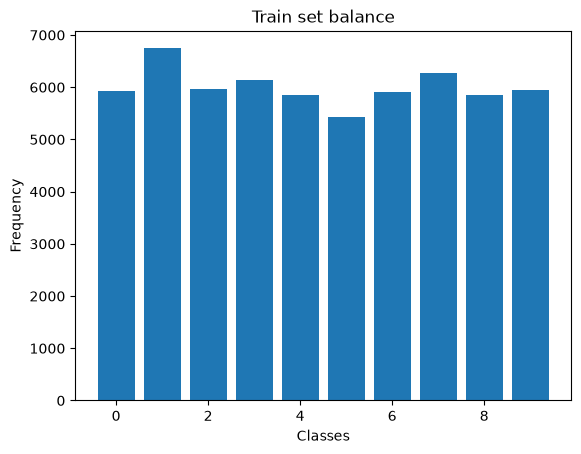

Testing set
(10000, 28, 28)
Minimum label occurence: 892


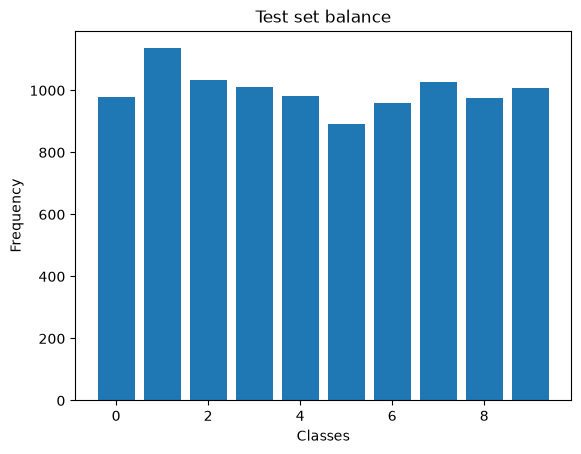

In [5]:
H, W, C     = 28, 28, 1
NUM_CLASSES = 10

# Building MNIST dataset
(x_mnist_train, y_mnist_train), (x_mnist_test, y_mnist_test) = tf.keras.datasets.mnist.load_data()

# Normalize dataset
x_mnist_train = normalize_dataset(x_mnist_train)
x_mnist_test = normalize_dataset(x_mnist_test)

print("Training set")
print(x_mnist_train.shape)
plot_dataset_balance(y_mnist_train, "Train")

print("Testing set")
print(x_mnist_test.shape)
plot_dataset_balance(y_mnist_test, "Test")

Balanced training set


100%|██████████| 10/10 [00:00<00:00, 34.44it/s]


(54210, 28, 28)
Minimum label occurence: 5421


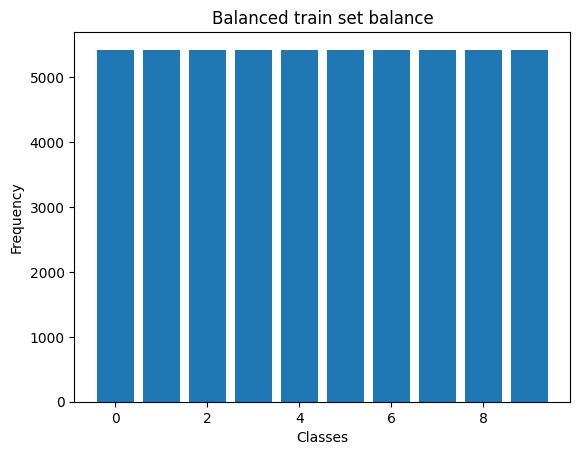

Balaned testing set


100%|██████████| 10/10 [00:00<00:00, 196.91it/s]

(8920, 28, 28)
Minimum label occurence: 892


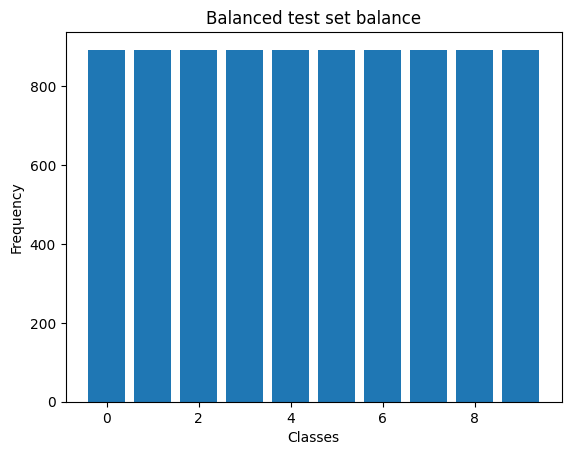

In [26]:
print("Balanced training set")
x_mnist_train, y_mnist_train = balance_dataset(x_mnist_train, y_mnist_train)
print(x_mnist_train.shape)
plot_dataset_balance(y_mnist_train, "Balanced train")

print("Balaned testing set")
x_mnist_test, y_mnist_test = balance_dataset(x_mnist_test, y_mnist_test)
print(x_mnist_test.shape)
plot_dataset_balance(y_mnist_test, "Balanced test")

# Shuffle train set
p = np.random.permutation(y_mnist_train.shape[0])
x_mnist_train = x_mnist_train[p]
y_mnist_train = y_mnist_train[p]

# Shuffle test set
p = np.random.permutation(y_mnist_test.shape[0])
x_mnist_test = x_mnist_test[p]
y_mnist_test = y_mnist_test[p]

/var/folders/sz/kmt03pkn5vv3_tlzq885vwdd7y_l80/T/ipykernel_32601/2830659759.py:46: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(num_rows, 2*num_cols, 2*i+2)


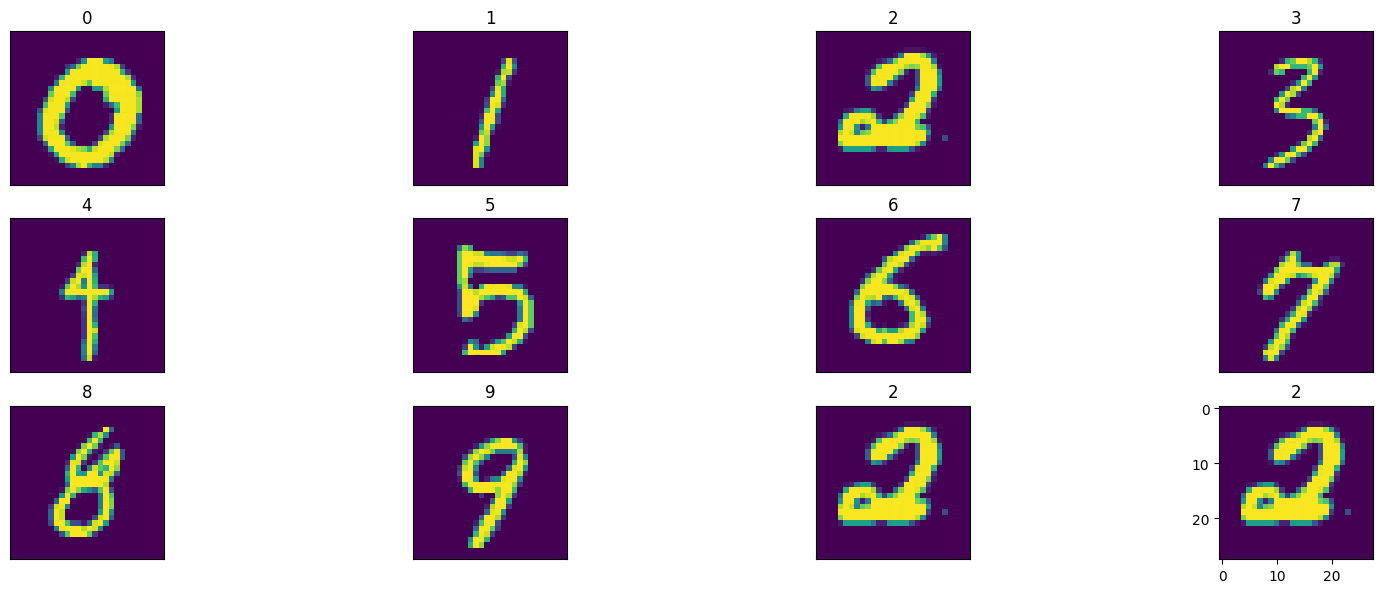

In [27]:
# Print an image of each class
x = np.array([x_mnist_train[np.where(y_mnist_train == i)[0][0]] for i in range(NUM_CLASSES)] + [x_mnist_train[0]]*(NUM_CLASSES%4))
y = np.array([y_mnist_train[np.where(y_mnist_train == i)[0][0]] for i in range(NUM_CLASSES)] + [y_mnist_train[0]]*(NUM_CLASSES%4))
plot_n_images(x.shape[0], x, y)

# MNIST finetuning

In [6]:
EPOCHS        = 20#50
LEARNING_RATE = 1e-3
BATCH_SIZE    = 128#256
LOSS_FUNCTION = tf.keras.losses.SparseCategoricalCrossentropy(from_logits = False)
OPTIMIZER     = tf.keras.optimizers.Adam(LEARNING_RATE)

In [7]:
model_mnist = tf.keras.models.Sequential([
    tf.keras.layers.Input((C*H*W)),
    tf.keras.layers.Dense(512, activation = "relu"),
    tf.keras.layers.Dense(256, activation = "relu"),
    tf.keras.layers.Dense(128, activation = "relu"),
    tf.keras.layers.Dense(64, activation = "relu"),
    tf.keras.layers.Dense(10, activation = "softmax")
])
model_mnist.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               401920    
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                                 
 dense_2 (Dense)             (None, 128)               32896     
                                                                 
 dense_3 (Dense)             (None, 64)                8256      
                                                                 
 dense_4 (Dense)             (None, 10)                650       
                                                                 
Total params: 575050 (2.19 MB)
Trainable params: 575050 (2.19 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [8]:
model_mnist.compile(
    optimizer = OPTIMIZER,
    loss      = LOSS_FUNCTION,
    metrics   = ["accuracy"]
)

Epoch 1/20


469/469 [==============================] - 4s 7ms/step - loss: 0.3199 - accuracy: 0.9018 - val_loss: 0.2029 - val_accuracy: 0.9382
Epoch 2/20
469/469 [==============================] - 3s 7ms/step - loss: 0.1395 - accuracy: 0.9568 - val_loss: 0.1087 - val_accuracy: 0.9662
Epoch 3/20
469/469 [==============================] - 3s 7ms/step - loss: 0.1019 - accuracy: 0.9682 - val_loss: 0.0986 - val_accuracy: 0.9691
Epoch 4/20
469/469 [==============================] - 3s 7ms/step - loss: 0.0827 - accuracy: 0.9738 - val_loss: 0.1050 - val_accuracy: 0.9674
Epoch 5/20
469/469 [==============================] - 3s 7ms/step - loss: 0.0698 - accuracy: 0.9781 - val_loss: 0.0924 - val_accuracy: 0.9732
Epoch 6/20
469/469 [==============================] - 3s 7ms/step - loss: 0.0620 - accuracy: 0.9801 - val_loss: 0.0840 - val_accuracy: 0.9756
Epoch 7/20
469/469 [==============================] - 3s 7ms/step - loss: 0.0552 - accuracy: 0.9826 - val_loss: 0.0811 - val_accuracy: 0.9757
Epoc

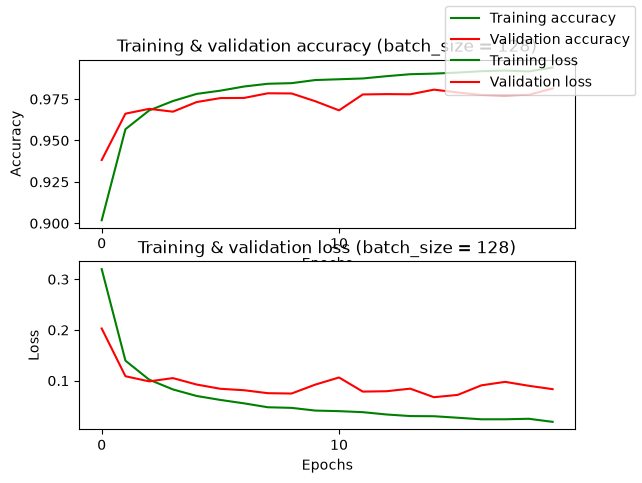

In [9]:
x_mnist_train = flatten_dataset(x_mnist_train)
#y_mnist_train = to_categorical(y_mnist_train)

x_mnist_test = flatten_dataset(x_mnist_test)
#y_mnist_test = to_categorical(y_mnist_test)

history_mnist = model_mnist.fit(
    x_mnist_train,
    y_mnist_train,
    epochs           = EPOCHS,
    batch_size       = BATCH_SIZE,
    validation_data  = (x_mnist_test, y_mnist_test)
)

plot_accuracy_loss(history_mnist, EPOCHS, BATCH_SIZE)

In [10]:
print("Evaluation on train set : ")
model_mnist.evaluate(x_mnist_train, y_mnist_train, verbose=2)

print("Evaluation on test set : ")
model_mnist.evaluate(x_mnist_test, y_mnist_test, verbose=2)

Evaluation on train set : 
1875/1875 - 3s - loss: 0.0161 - accuracy: 0.9949 - 3s/epoch - 1ms/step
Evaluation on test set : 
313/313 - 0s - loss: 0.0833 - accuracy: 0.9814 - 467ms/epoch - 1ms/step


[0.08325397968292236, 0.9814000129699707]

313/313 [==============================] - 1s 2ms/step


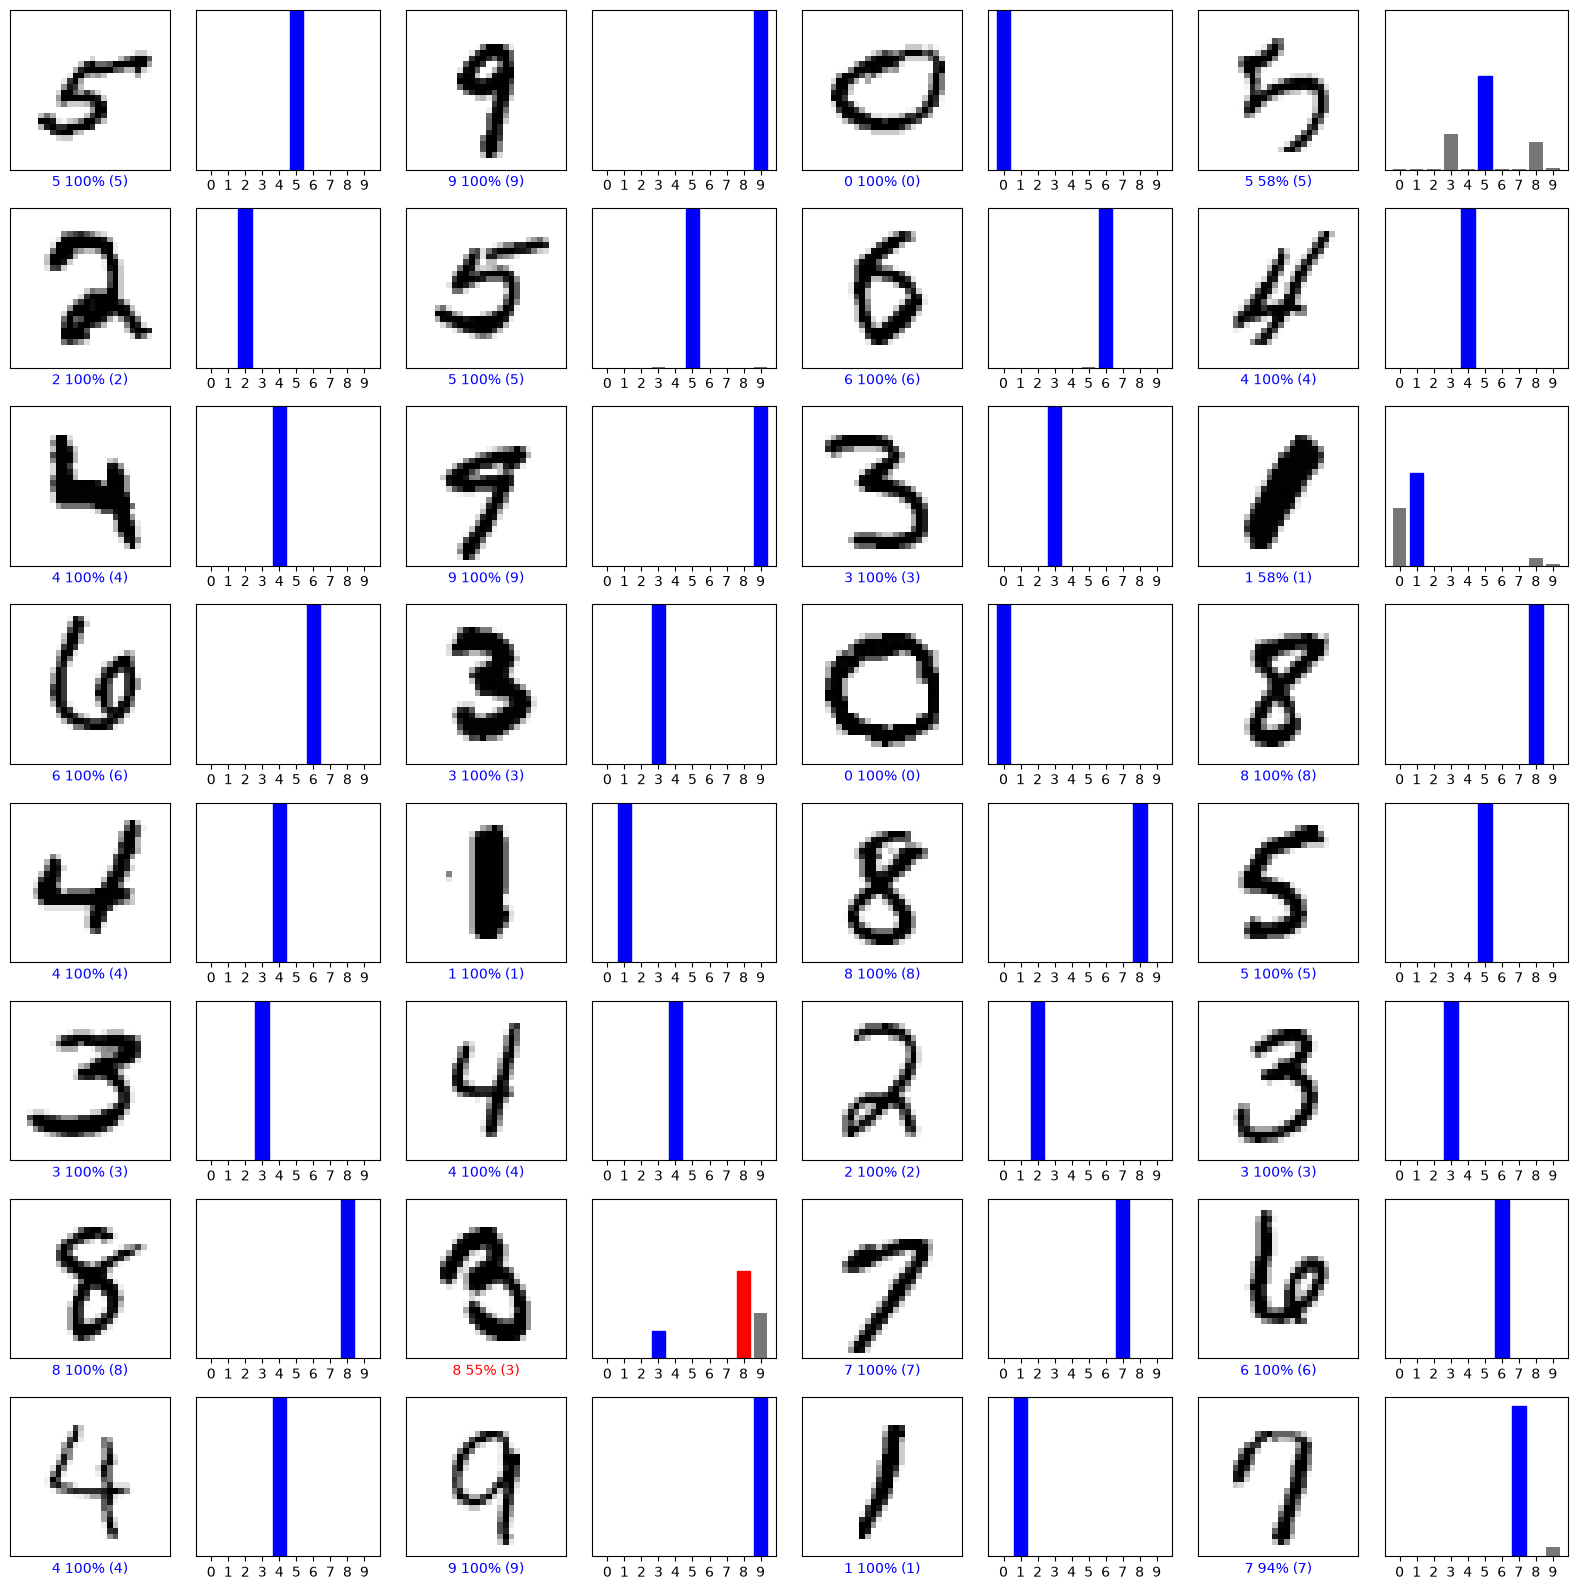

In [11]:
predictions = model_mnist.predict(x_mnist_test)
print_prediction(32, x_mnist_test.reshape((-1, H, W))+0.5, y_mnist_test, predictions, num_classes = NUM_CLASSES)

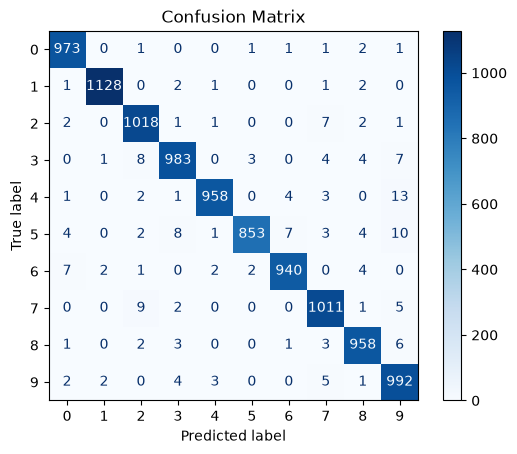

In [12]:
cm = confusion_matrix(y_mnist_test, np.argmax(predictions, axis = 1))
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = [str(i) for i in range(NUM_CLASSES)])
disp.plot(cmap = 'Blues')
plt.title("Confusion Matrix")
plt.show()

In [17]:
# Save model and its metadata
model_name = "models/5dense-mnist-10class-finetuned.h5"
model_mnist.save(model_name)
with open(model_name + "-history.json", "w") as f:
    json.dump(history_mnist.history, f)

c:\Users\foltz\Documents\ISMIN\3A\Embedded_Systems\Embedded Neural Network on MCU\Projet_Embedded_AI_MCU\.venv\Lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [19]:
# Reload model and its metadata
model_mnist_name = "models/5dense-mnist-10class-finetuned.h5"
model_mnist = tf.keras.models.load_model(model_mnist_name)
class History:
    def __init__(self):
        self.history = {}
        self.epoch   = 0
history_mnist = History()
with open(model_mnist_name + "-history.json", 'r') as f:
    history_mnist.history = json.load(f)
history_mnist.epoch       = list(range(len(history_mnist.history["loss"])))

Communication avec STM32 pour tester le MLP

In [2]:
import serial
import numpy as np
import tensorflow as tf

PORT = "COM7"


def load_test_set():
    """
    Reconstruit le jeu de test MNIST avec exactement le pretraitement utilise
    a l'entrainement (voir emnist.ipynb : normalize_dataset / flatten_dataset).

    Les anciens fichiers MNIST_xtest_NN_C2_16_10.npy / MNIST_ytest_NN_C2_16_10.npy
    (herites d'un autre TP) sont normalises en [0, 1], alors que le modele est
    entraine sur des pixels en [-0.5, 0.5] ((pixel/255) - 0.5). Envoyer les
    mauvaises donnees ne fait planter ni le protocole ni la carte : la carte
    repond toujours, mais avec des predictions degradees. Verifie en local :
    98.14% de precision avec la bonne normalisation, 82.2% avec l'ancienne
    (mesure sur le meme modele, en float32, sans STM32 ni compression).

    Returns:
        tuple: (X_test, Y_test) - images aplaties en (N, 784) float32 dans
        [-0.5, 0.5], labels en one-hot (N, 10).
    """
    (_, _), (x_raw, y_raw) = tf.keras.datasets.mnist.load_data()
    x_test = ((x_raw / 255) - 0.5).astype(np.float32).reshape(x_raw.shape[0], -1)
    y_test = np.eye(10)[y_raw].astype(np.float32)
    return x_test, y_test


def synchronise_UART(serial_port):
    """
    Synchronizes the UART communication by sending a byte and waiting for a response.

    Args:
        serial_port (serial.Serial): The serial port object to use for communication.

    Returns:
        None
    """
    while (1):
        serial_port.write(b"\xAB")
        ret = serial_port.read(1)
        if (ret == b"\xCD"):
            serial_port.read(1)
            break


def send_inputs_to_STM32(inputs, serial_port):
    """
    Sends a numpy array of inputs to the STM32 microcontroller via a serial port.

    Args:
        inputs (numpy.ndarray): The inputs to send to the STM32.
        serial_port (serial.Serial): The serial port to use for communication.

    Returns:
        None
    """
    inputs = inputs.astype(np.float32)
    buffer = b""
    for x in inputs:
        buffer += x.tobytes()
    serial_port.write(buffer)


def read_output_from_STM32(serial_port):
    """
    Reads 10 bytes from the given serial port and returns a list of float values obtained by dividing each byte by 255.

    Args:
    serial_port: A serial port object.

    Returns:
    A list of float values obtained by dividing each byte by 255.
    """
    output = serial_port.read(10)

    float_values = [int(out)/255 for out in output]
    return float_values


def evaluate_model_on_STM32(iterations, serial_port):
    """
    Evaluates the accuracy of a machine learning model on an STM32 device.

    Args:
        iterations (int): The number of iterations to run the evaluation for.
        serial_port (Serial): The serial port object used to communicate with the STM32 device.

    Returns:
        float: The accuracy of the model, as a percentage.
    """
    accuracy = 0
    for i in range(iterations):
        print(f"----- Iteration {i+1} -----")
        send_inputs_to_STM32(X_test[i], serial_port)
        output = read_output_from_STM32(serial_port)
        if (np.argmax(output) == np.argmax(Y_test[i])):
            accuracy += 1 / iterations
        print(f"   Expected output: {Y_test[i]}")
        print(f"   Received output: {output}")
        print(f"----------------------- Accuracy: {accuracy:.2f}\n")
    return accuracy


if __name__ == '__main__':
    X_test, Y_test = load_test_set()

    with serial.Serial(PORT, 115200, timeout=1) as ser:
        print("Synchronising...")
        synchronise_UART(ser)
        print("Synchronised")

        print("Evaluating model on STM32...")
        error = evaluate_model_on_STM32(100, ser)


Synchronising...
Synchronised
Evaluating model on STM32...
----- Iteration 1 -----
   Expected output: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
   Received output: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.996078431372549, 0.0, 0.0]
----------------------- Accuracy: 0.01

----- Iteration 2 -----
   Expected output: [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
   Received output: [0.0, 0.0, 0.996078431372549, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
----------------------- Accuracy: 0.02

----- Iteration 3 -----
   Expected output: [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
   Received output: [0.0, 0.996078431372549, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
----------------------- Accuracy: 0.03

----- Iteration 4 -----
   Expected output: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
   Received output: [0.996078431372549, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
----------------------- Accuracy: 0.04

----- Iteration 5 -----
   Expected output: [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
   Received output: [0.0, 0.0, 0.0, 0.0, 0.996078431372549, 0

# Model deployment using AIfES-Converter

In [ ]:
NUM_CLASSES = 10
NUM_PICTURES = 10
x_mnist_train = x_mnist_train[:NUM_PICTURES]
x_mnist_test = x_mnist_test[:NUM_PICTURES]
y_mnist_train = y_mnist_train[:NUM_PICTURES]
y_mnist_test = y_mnist_test[:NUM_PICTURES]

In [ ]:
BASE_PATH    = "."
MODEL_TYPE   = "mlp"
DATASET_NAME = "mnist"

# ATTENTION : keras2aifes attend un objet keras.Model, pas un chemin de
# fichier. model_mnist (charge/entraine plus haut dans le notebook) est le
# bon objet a utiliser ici.
MODEL = model_mnist

test_name   = f"{DATASET_NAME}-{MODEL_TYPE}-{len(MODEL.layers)}layers"
output_path = f"{BASE_PATH}/aifes_f32/{test_name}"

# Export F32 : genere aifes_f32_fnn.h (structure du reseau) et
# aifes_f32_weights.h (poids a plat) dans output_path.
#
# Note : convert_to_fnn_f32() de la version installee (AIfES-Converter 1.0.0)
# n'accepte que (keras_model, output_path, with_weights). Les parametres
# train_set_size/test_set_size/loss/optimizer/frozen_layers de versions plus
# recentes de l'API (pour l'entrainement embarque) ne sont pas disponibles ici.
keras2aifes.convert_to_fnn_f32(
    MODEL,
    output_path,
    with_weights=True,
)

print("Code C AIfES genere dans :", output_path)
